# 三个数据集的最新 Val RD 对比

本 notebook 不使用旧绘图代码中手写的数据，只读取重新执行 `evaluate_three_datasets_val.py` 生成的汇总 CSV。

- Landsat8: 200 张 val，归一化 `/65535`
- RS: 200 张 val，归一化 `/65535`（与本表所有旧 RS 权重的训练配置一致）
- FMoW8: 300 张 val，归一化 `/4096`
- BPP: forward likelihood BPP，不是真实码流字节 BPP
- MS-SSIM: `-10 log10(1-MS-SSIM)` dB
- 未来用 `/32767` 重训的 RS 模型属于新协议，不能与本表旧权重混合


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/data/huzhenghao/ml/h/并行优化')
CSV_PATH = ROOT / 'results/data/three_datasets_val_rd.csv'
rd = pd.read_csv(CSV_PATH)
rd = rd.sort_values(['dataset', 'method', 'bpp']).reset_index(drop=True)
print(f'汇总点数: {len(rd)}  |  协议: {rd.protocol.unique().tolist()}')
display(rd)


汇总点数: 178  |  协议: ['val_forward_likelihood_bpp']


,dataset,method,lambda,images,normalization,bpp,psnr,ms_ssim_db,bpp_std,psnr_std,ms_ssim_db_std,checkpoint_epoch,checkpoint,protocol,elapsed_seconds
0,fmow8,ELIC,1024,300,4096.0,0.070161,34.481877,14.575093,0.063242,2.695370,2.846063,NaN,/data/huzhenghao/ml/test/pth/elic/fmow8/1024.p...,val_forward_likelihood_bpp,9.434251
1,fmow8,ELIC,2048,300,4096.0,0.124345,38.121099,17.447999,0.106704,2.817220,3.218362,NaN,/data/huzhenghao/ml/test/pth/elic/fmow8/2048.p...,val_forward_likelihood_bpp,10.077547
2,fmow8,ELIC,4096,300,4096.0,0.211364,40.422770,19.653595,0.172070,2.893863,3.311053,NaN,/data/huzhenghao/ml/test/pth/elic/fmow8/4096.p...,val_forward_likelihood_bpp,9.977041
3,fmow8,ELIC,8192,300,4096.0,0.326422,42.649911,21.706710,0.245805,3.118986,3.191235,NaN,/data/huzhenghao/ml/test/pth/elic/fmow8/8192.p...,val_forward_likelihood_bpp,10.143641
4,fmow8,ELIC,16384,300,4096.0,0.484380,45.099963,23.616201,0.340020,3.456476,3.347270,NaN,/data/huzhenghao/ml/test/pth/elic/fmow8/16384....,val_forward_likelihood_bpp,10.352422
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,rs,RWK,65536,200,65535.0,0.342733,52.535536,28.375412,0.162011,3.780729,3.777305,NaN,/data/huzhenghao/ml/test/pth/rwk/rs/65536.pth.tar,val_forward_likelihood_bpp,17.910061
174,rs,RWK,131071,200,65535.0,0.541837,53.861792,30.086931,0.237363,3.537202,3.518135,NaN,/data/huzhenghao/ml/test/pth/rwk/rs/131071.pth...,val_forward_likelihood_bpp,18.168272
175,rs,RWK,262144,200,65535.0,0.851017,55.934394,32.400672,0.357355,3.932999,3.723826,NaN,/data/huzhenghao/ml/test/pth/rwk/rs/262144.pth...,val_forward_likelihood_bpp,15.656513
176,rs,RWK,393216,200,65535.0,1.071400,56.741529,33.436172,0.432084,3.802721,3.619952,NaN,/data/huzhenghao/ml/test/pth/rwk/rs/393216.pth...,val_forward_likelihood_bpp,20.540659


In [4]:
# 核对每条曲线的 val 样本数和 RD 点数
coverage = (rd.groupby(['dataset', 'method'])
              .agg(points=('lambda', 'count'), images=('images', 'first'),
                   normalization=('normalization', 'first'))
              .reset_index())
display(coverage)


,dataset,method,points,images,normalization
0,fmow8,ELIC,7,300,4096.0
1,fmow8,FTIC,7,300,4096.0
2,fmow8,HL,7,300,4096.0
3,fmow8,HPCM,7,300,4096.0
4,fmow8,Hybrid-Parallel,7,300,4096.0
5,fmow8,MLIC,7,300,4096.0
6,fmow8,Our-Original,7,300,4096.0
7,fmow8,RWK,7,300,4096.0
8,landsat8,ELIC,7,200,65535.0
9,landsat8,FTIC,7,200,65535.0


In [5]:
# 按 tttforFmow8.ipynb 的形式生成可直接复制的数据字典
datasets_rd = {}
for dataset_name, dataset_rows in rd.groupby('dataset', sort=False):
    datasets_rd[dataset_name] = {}
    for method, rows in dataset_rows.groupby('method', sort=False):
        datasets_rd[dataset_name][method] = [
            (float(r.bpp), float(r.psnr), float(r.ms_ssim_db))
            for r in rows.sort_values('bpp').itertuples()
        ]
datasets_rd


{'fmow8': {'ELIC': [(0.070161359894167, 34.48187733968099, 14.575093444188436),
   (0.1243449116568081, 38.12109945933024, 17.447999280293782),
   (0.211363998237842, 40.42276995340983, 19.653594805399575),
   (0.3264223214549323, 42.64991055806478, 21.706709750493367),
   (0.4843801703412707, 45.09996308644613, 23.6162011273702),
   (0.7070695180585608, 46.91209701538086, 25.27690762837728),
   (0.9760088706140716, 48.19288888295492, 26.72994369506836)],
  'FTIC': [(0.0641044204666589, 39.95134893417358, 17.187280480066935),
   (0.0986608784397443, 40.86562800725301, 18.345800224939985),
   (0.1511425163721045, 42.24168751398722, 19.78985453923543),
   (0.2528962917703514, 43.65800848642985, 21.4689199701945),
   (0.3712871307569245, 44.84419396718343, 22.865183057785035),
   (0.5452540894349416, 46.20180220286051, 24.485841751098636),
   (0.7728262844371299, 47.49773178100586, 25.99509652455648)],
  'HL': [(0.0478789821854055, 38.49905723571777, 15.71444650332133),
   (0.094850850926

In [6]:
colors = {
    'ELIC': '#1f77b4', 'RWK': '#ff7f0e', 'HL': "#fff12d",
    'MLIC': '#9467bd', 'FTIC': '#8c564b', 'HPCM': '#23201f',
    'Our-Original': '#e377c2', 'Hybrid-Parallel': '#00a878',
}
titles = {'landsat8': 'Landsat8', 'rs': 'RS', 'fmow8': 'FMoW8'}

def plot_metric(dataset_name, metric, ylabel):
    subset = rd[rd.dataset.eq(dataset_name)]
    plt.figure(figsize=(10, 6))
    for method, rows in subset.groupby('method', sort=False):
        rows = rows.sort_values('bpp')
        plt.plot(rows.bpp, rows[metric], label=method, marker='o',
                 linewidth=1.8, markersize=5, color=colors.get(method))
    plt.xlabel('BPP (likelihood)')
    plt.ylabel(ylabel)
    plt.title(f'{titles[dataset_name]} - {ylabel} vs BPP')
    plt.grid(True, linestyle='--', alpha=0.30)
    plt.legend(ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()


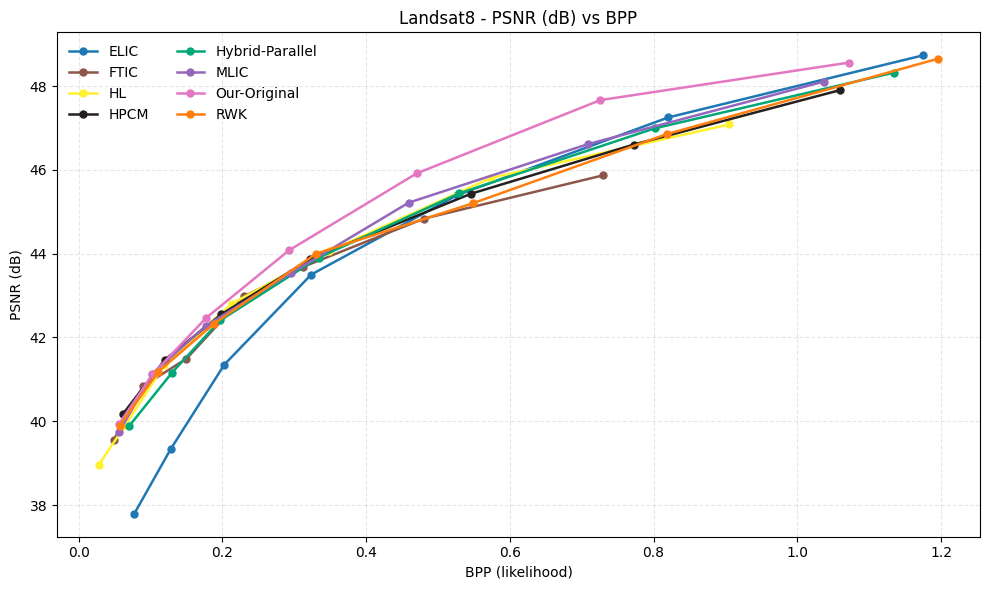

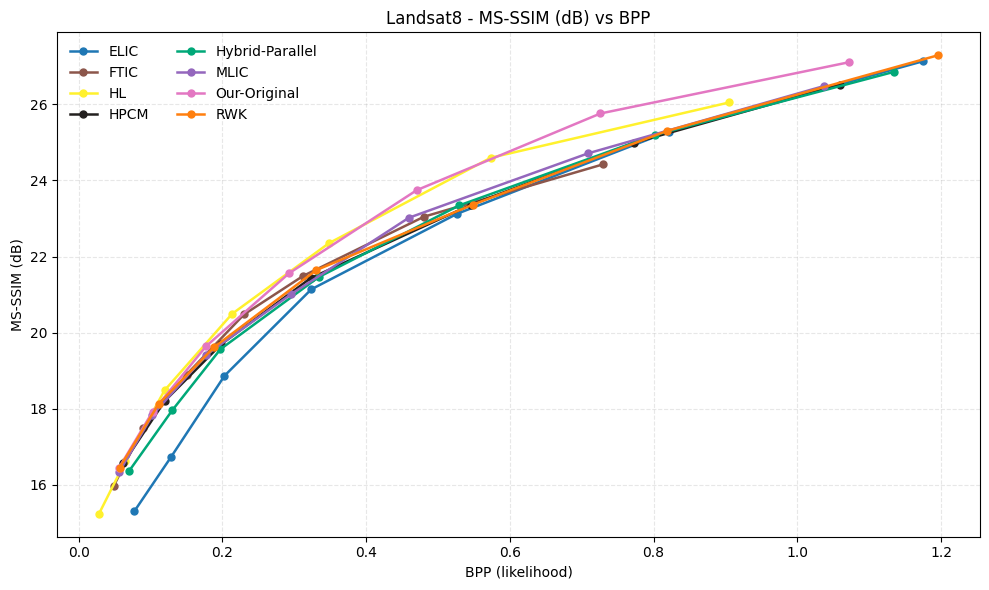

In [7]:
# Landsat8：两张独立图
plot_metric('landsat8', 'psnr', 'PSNR (dB)')
plot_metric('landsat8', 'ms_ssim_db', 'MS-SSIM (dB)')


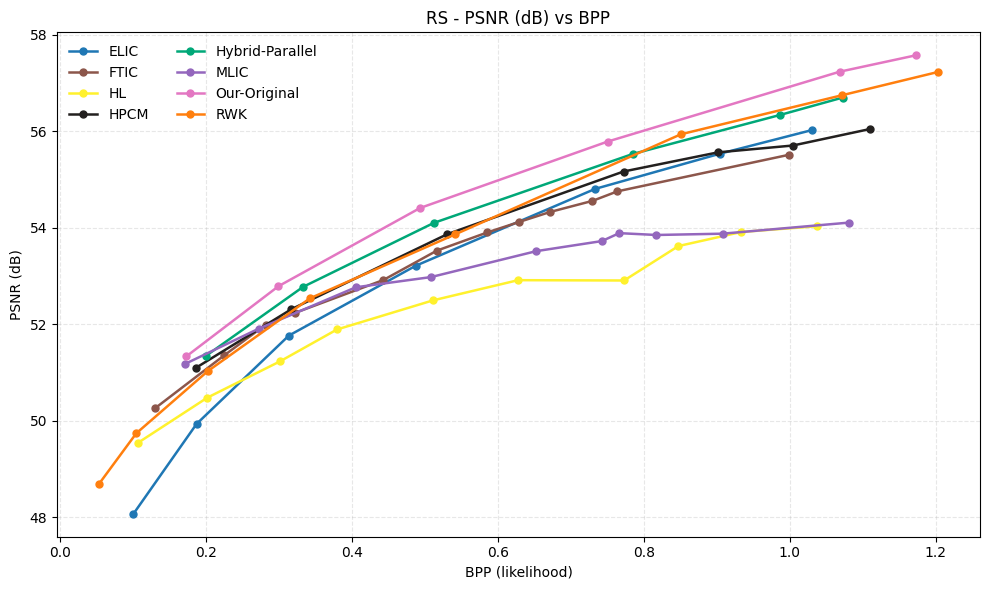

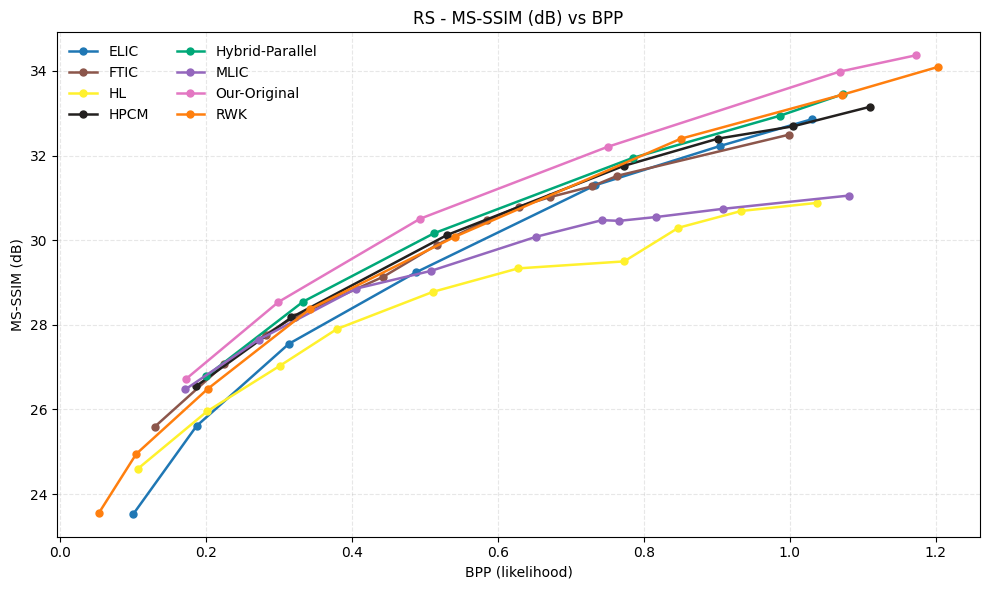

In [8]:
# RS：两张独立图
plot_metric('rs', 'psnr', 'PSNR (dB)')
plot_metric('rs', 'ms_ssim_db', 'MS-SSIM (dB)')


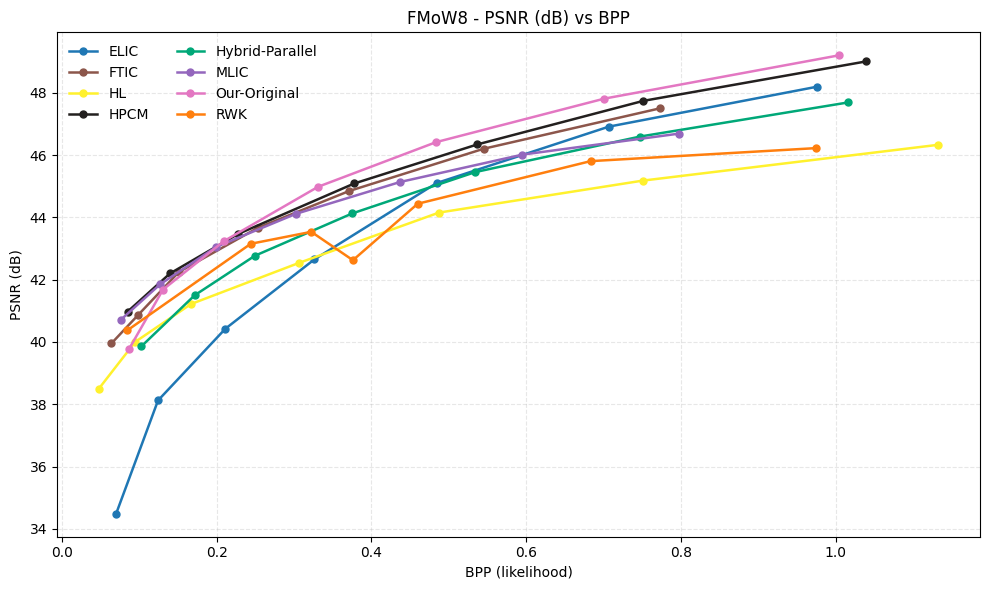

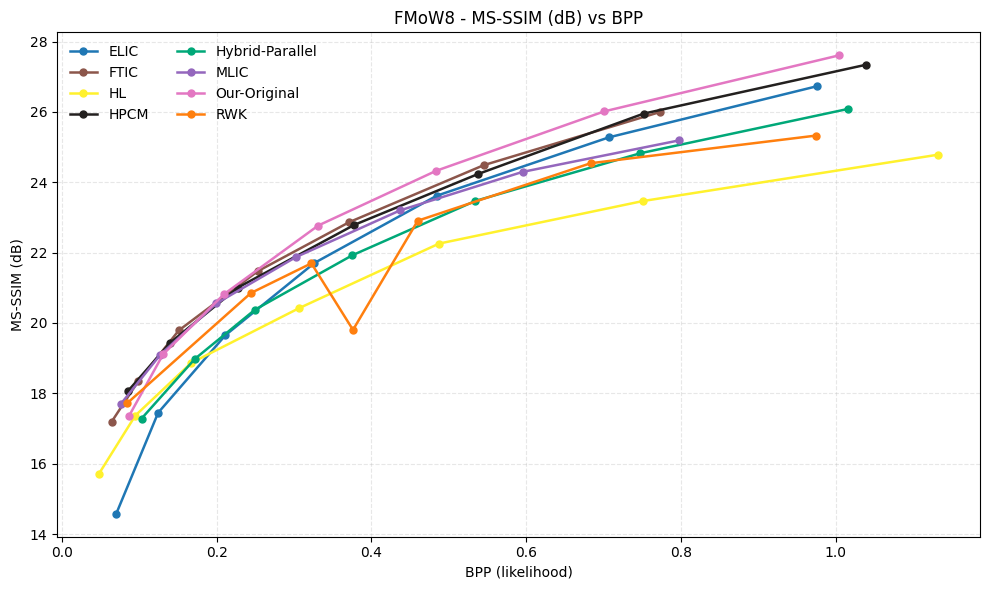

In [9]:
# FMoW8：两张独立图
plot_metric('fmow8', 'psnr', 'PSNR (dB)')
plot_metric('fmow8', 'ms_ssim_db', 'MS-SSIM (dB)')
